# Session 3 — Four Ways to Draw a Boundary

In Session 2 a logistic regression was the last step of a pipeline, and we never asked whether it was a good choice. This session puts four common model families on the same problem and looks at what each one does with it.

Every model has a built-in preference for a certain kind of answer. Logistic regression draws a straight line. k-nearest neighbours copies the labels of nearby points. A decision tree asks a series of yes/no questions about one feature at a time. A random forest averages many such trees. These preferences are called the model's **inductive bias**, and they decide which patterns a model can find from the examples it is given.

**By the end of the session you should be able to:**

1. describe in a sentence how each of the four models makes a prediction;
2. read a decision boundary and say what the model can and can't express;
3. spot overfitting as a gap between training and test accuracy, and see where it comes from.

**To run it yourself** you need `numpy`, `pandas`, `matplotlib` and `scikit-learn`. The outputs are already saved in the notebook. It runs in under a minute, and your numbers may differ slightly from the ones quoted in the text.

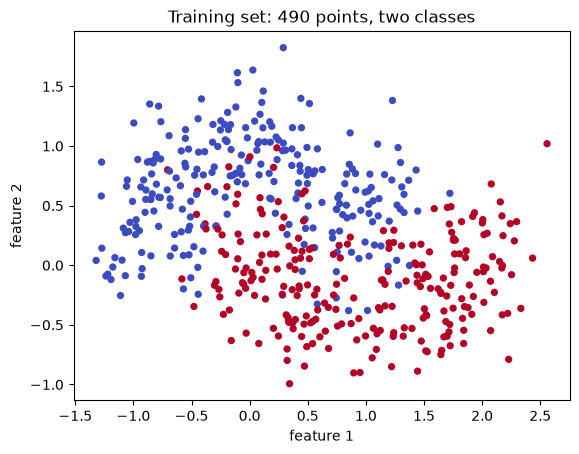

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier

SEED = 42
X, y = make_moons(n_samples=700, noise=0.28, random_state=SEED)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, stratify=y, random_state=SEED)

plt.scatter(*X_train.T, c=y_train, cmap="coolwarm", s=18)
plt.xlabel("feature 1")
plt.ylabel("feature 2")
plt.title(f"Training set: {len(X_train)} points, two classes")
plt.show()

## The data

Two interleaved half-moons of points, 700 in all, with noticeable noise so the classes overlap. We train on 490 and keep 210 for testing. The task is to colour the plane red or blue. Each classifier below sees the same split, and we score them all with accuracy, so any difference comes from the model alone.

In [2]:
def plot_boundary(ax, model, title, X=X_test, y=y_test):
    xx, yy = np.meshgrid(np.linspace(X[:, 0].min() - 0.6, X[:, 0].max() + 0.6, 300), np.linspace(X[:, 1].min() - 0.6, X[:, 1].max() + 0.6, 300))
    zz = model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, zz, levels=[-0.5, 0.5, 1.5], colors=["#c9daf0", "#f6cfc4"])
    ax.scatter(*X.T, c=y, cmap="coolwarm", s=14, edgecolor="k", linewidth=0.3)
    ax.set(title=title, xticks=[], yticks=[])


def accuracies(model):
    return model.score(X_train, y_train), model.score(X_test, y_test)

Two small helpers: `plot_boundary` shades the plane by what a model predicts at each location, and `accuracies` returns a model's training and test accuracy. You don't need to read this cell during the session.

In [3]:
models = {
    "Logistic regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=SEED)),
    "k-nearest neighbours": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=17)),
    "Decision tree (depth 5)": DecisionTreeClassifier(max_depth=5, min_samples_leaf=8, random_state=SEED),
    "Random forest": RandomForestClassifier(n_estimators=200, max_depth=6, min_samples_leaf=4, random_state=SEED, n_jobs=-1),
}
rows = []
for name, model in models.items():
    model.fit(X_train, y_train)
    rows.append({"model": name, "train accuracy": accuracies(model)[0], "test accuracy": accuracies(model)[1]})
pd.DataFrame(rows).set_index("model").round(3)

,train accuracy,test accuracy
model,,
Logistic regression,0.867,0.852
k-nearest neighbours,0.900,0.919
Decision tree (depth 5),0.914,0.914
Random forest,0.914,0.910


## 1. Four models, one protocol

- **Logistic regression** gives each feature a weight and adds them up. In two dimensions the boundary between the classes is a straight line.
- **k-nearest neighbours** finds the 17 training points closest to a new point and takes a vote.
- **A decision tree** splits the plane with rules like "feature 1 < 0.3", choosing each split to make the groups on either side as pure as possible. We limit this one to depth 5.
- **A random forest** trains 200 trees on random samples of the data and averages their votes.

> **Pause:** the moons are curved. Before looking at the boundaries, which models do you expect to follow the curve and which to struggle?
>
> - **A.** All four follow the curve about equally.
> - **B.** k-NN follows the curve best, and logistic regression struggles most.
> - **C.** The tree and the forest follow it best, because they are the most flexible.
> - **D.** Logistic regression does best, because it is the simplest.
>
> Pick one before you scroll.

<details><summary>Answer</summary>

**B.** Logistic regression is lowest (0.852 on the test set), and k-NN bends its boundary around the local points. The tree and the forest use rectangles, so their boundaries can't follow the curve smoothly; the other three are within a point of each other (0.910 to 0.919).

</details>

The table lists training and test accuracy. Logistic regression is lowest, at 0.852 on the test set. The other three are within 1 point of each other (0.910 to 0.919). With 210 test points, each point is worth 0.5 percentage points, so a 1-point gap is two points of the test set and shouldn't be read as a ranking.

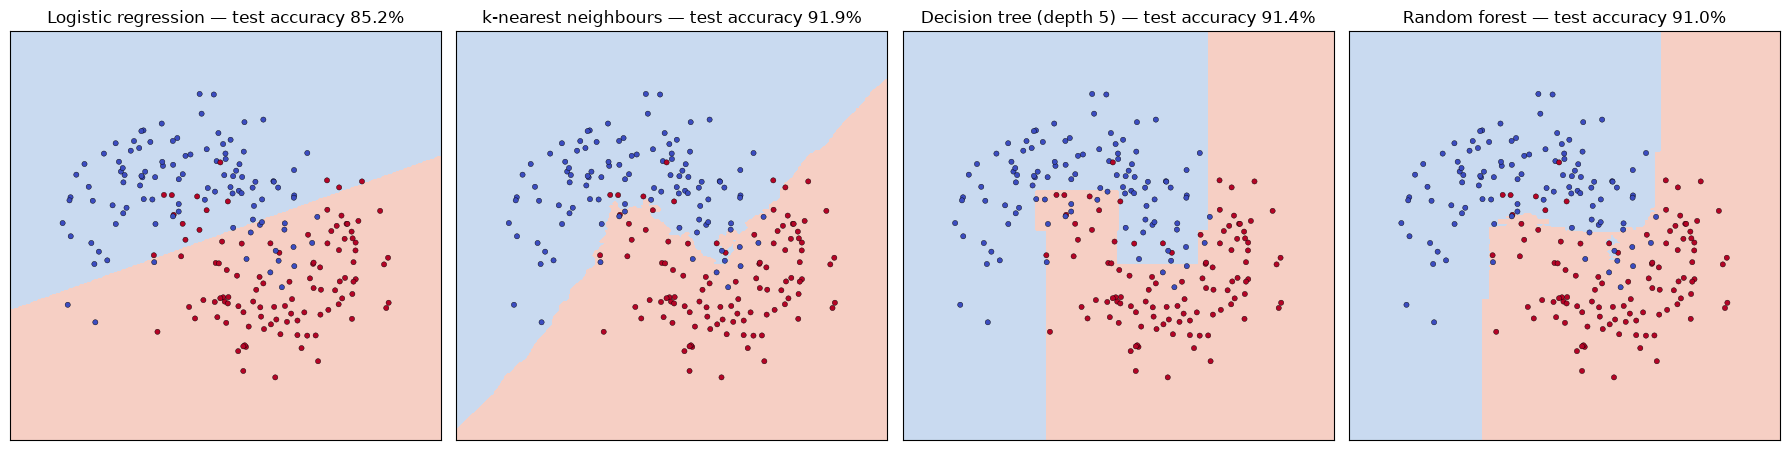

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4.6))
for ax, (name, model) in zip(axes, models.items()):
    plot_boundary(ax, model, f"{name} — test accuracy {model.score(X_test, y_test):.1%}")
plt.tight_layout()
plt.show()

The line cuts through both moons, which is the most a single straight boundary can do, and it costs about 7 points of accuracy. k-NN bends its boundary around the local arrangement of points and follows the curve best. The tree and the forest use rectangles, because every rule looks at one feature. The forest averages 200 trees, but its boundary is still built from rectangles.

Three of the four models sit at 91–92% on the test set. The remaining errors come from points that sit in the other class's territory because of the noise, and no boundary can classify those correctly.

Training and test accuracy are close for all four. The k-NN model scores higher on the test set (0.919) than on the training set (0.900). This is chance: the 210 test points happened to be slightly easier. None of these four models is overfitting, so the table can't show us what overfitting looks like. For that we need a model with no limits.

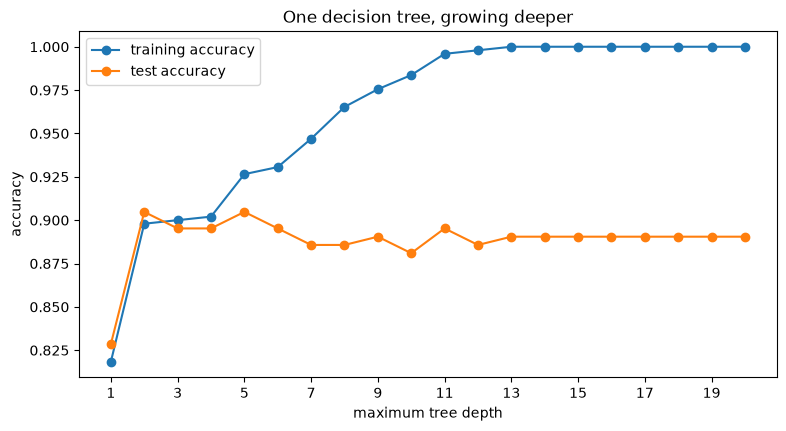

Best test accuracy 0.905 at depth 2
No depth limit: the tree reaches depth 13 with 58 leaves


,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
train,0.818,0.898,0.900,0.902,0.927,0.931,0.947,0.965,0.976,0.984,0.996,0.998,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00
test,0.829,0.905,0.895,0.895,0.905,0.895,0.886,0.886,0.890,0.881,0.895,0.886,0.89,0.89,0.89,0.89,0.89,0.89,0.89,0.89


In [5]:
depths = range(1, 21)
fits = [DecisionTreeClassifier(max_depth=d, random_state=SEED).fit(X_train, y_train) for d in depths]
curve = pd.DataFrame([accuracies(m) for m in fits], index=depths, columns=["train", "test"])

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(curve.index, curve["train"], marker="o", label="training accuracy")
ax.plot(curve.index, curve["test"], marker="o", label="test accuracy")
ax.set(xlabel="maximum tree depth", ylabel="accuracy", title="One decision tree, growing deeper")
ax.set_xticks(range(1, 21, 2))
ax.legend()
plt.show()

best_depth = curve["test"].idxmax()
print(f"Best test accuracy {curve['test'].max():.3f} at depth {best_depth}")
print(f"No depth limit: the tree reaches depth {fits[-1].get_depth()} with {fits[-1].get_n_leaves()} leaves")
curve.round(3).T

## 2. Overfitting: a tree with no limits

A tree can keep splitting until every training point has its own region. We vary the maximum depth from 1 to 20 and record both accuracies each time.

> **Pause:** as the tree gets deeper, training accuracy will rise. What do you expect test accuracy to do?
>
> - **A.** It rises too, only more slowly.
> - **B.** It peaks early, then stays a little lower.
> - **C.** It falls sharply once the tree starts memorising the training points.
>
> Pick one before you scroll.

<details><summary>Answer</summary>

**B.** Test accuracy peaks at 0.905 at depth 2 and then stays between 0.881 and 0.895, while training accuracy reaches 1.000 at depth 13. The 11-point gap is overfitting, but the fall in test accuracy is small.

</details>

Training accuracy climbs steadily and reaches 1.000 at depth 13, where the tree has 58 leaves. Test accuracy does not follow it. It peaks early, at 0.905 for depth 2 (and again for depth 5), and from depth 7 onwards it stays between 0.881 and 0.895. After depth 13 the tree cannot grow any more, and both lines go flat: 1.000 on the training set and 0.890 on the test set.

That 11-point gap is **overfitting**. The deep tree has memorised the training points, including the noisy ones, so its training accuracy no longer tells us anything about new data. A model's training score can only be trusted when the test score agrees with it.

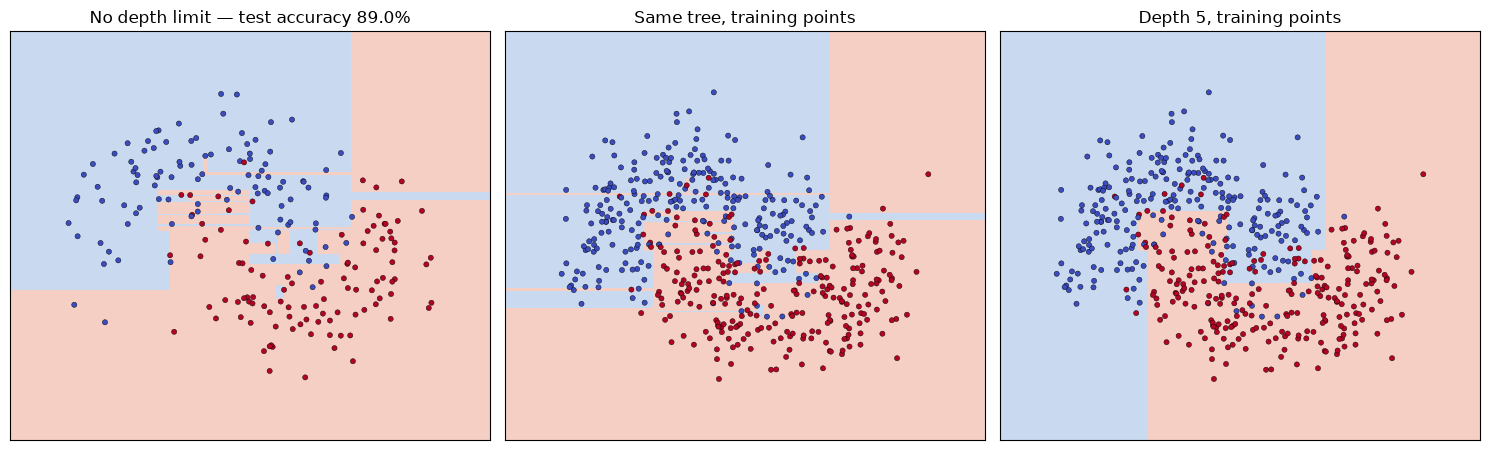

Unlimited tree: train 1.000, test 0.890


In [6]:
unlimited = DecisionTreeClassifier(random_state=SEED).fit(X_train, y_train)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
plot_boundary(axes[0], unlimited, f"No depth limit — test accuracy {unlimited.score(X_test, y_test):.1%}")
plot_boundary(axes[1], unlimited, "Same tree, training points", X_train, y_train)
plot_boundary(axes[2], models["Decision tree (depth 5)"], "Depth 5, training points", X_train, y_train)
plt.tight_layout()
plt.show()
print("Unlimited tree: train %.3f, test %.3f" % accuracies(unlimited))

The left plot shows the unlimited tree on the test points; the middle plot shows the same tree on the training points it was fitted to. In the middle plot the tree has carved out small boxes around individual red points inside the blue region and the reverse, so that every training point is on the right side. Those boxes are fitted to noise. On the test points (left) the same boxes catch the wrong points. The depth-5 tree on the right has a few large regions and makes more training errors, which is why its test score holds up.

Notice how small the cost is in test accuracy: 0.890 against 0.905 at best. The cost of overfitting here is mostly a misleading training score, and a more complicated model that is no better. On smaller datasets or more flexible models (Session 7) the damage to test accuracy is much larger.

In [7]:
X_stretched = X.copy()
X_stretched[:, 0] *= 1000
Xs_train, Xs_test, ys_train, ys_test = train_test_split(X_stretched, y, test_size=0.30, stratify=y, random_state=SEED)

raw_knn = KNeighborsClassifier(n_neighbors=17).fit(Xs_train, ys_train)
scaled_knn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=17)).fit(Xs_train, ys_train)
print(f"k-NN without scaling: {raw_knn.score(Xs_test, ys_test):.3f}")
print(f"k-NN with scaling:    {scaled_knn.score(Xs_test, ys_test):.3f}")

k-NN without scaling: 0.705
k-NN with scaling:    0.919


## 3. Why scaling changes k-NN

k-NN works from distances, so the units of each feature matter. Here we multiply feature 1 by 1,000, as if it were measured in millimetres and the other in metres, and run k-NN again.

Without scaling the test accuracy drops from 0.919 to 0.705, because feature 1 now dominates every distance and feature 2 is almost ignored. With `StandardScaler` in front, the accuracy returns to 0.919: the scaler puts the two features on the same footing, so the stretching makes no difference.

Trees aren't affected, since a rule like "feature 1 < 300" can be rewritten for any rescaling of that feature. Whether preprocessing matters depends on the model, which is why the scaler lives in the pipeline with the model.

## Practical takeaways

- Start with a simple model and one fair protocol (same split, same metric), then add complexity only when it earns it.
- Compare training and test accuracy for every model. A large gap means overfitting; a small gap with a low score means the model is too simple or the features are too weak.
- Differences of a point or two on a small test set don't rank models.
- Scale features for distance-based models (k-NN) and for logistic regression; trees don't need it.
- Pick the model family by what you believe about the data: straight-line patterns suit logistic regression, local similarity suits k-NN, readable rules suit trees, and a forest is a strong default when you want accuracy without much tuning.
- For tables of data in practice, the usual first choice is **gradient-boosted trees**: scikit-learn's `HistGradientBoostingClassifier`, or the XGBoost and LightGBM libraries. They are not run here; Going deeper says how they differ from a forest.

---

# Going deeper

*The rest of this notebook is for reading after the session.*

## Logistic regression

The model computes a score $z=w^\top x+b$ and turns it into a probability with the sigmoid function

$$
\sigma(z)=\frac{1}{1+e^{-z}} .
$$

The boundary is where the probability is 0.5, which is where $z=0$. In two dimensions that is the line $w_1x_1+w_2x_2+b=0$.

## k-nearest neighbours

For a new point $x$, k-NN finds the $k$ training points with the smallest Euclidean distance

$$
d(x,z)=\sqrt{\sum_{j}(x_j-z_j)^2}
$$

and returns the majority label. A small $k$ gives a flexible, jagged boundary. A large $k$ gives a smoother one that can wash out small structures. With $k=1$ the training accuracy is always 1.0, for the same reason as the unlimited tree.

## Decision trees and Gini impurity

A split is chosen to reduce the **Gini impurity** of the groups it creates:

$$
G=1-\sum_{k}p_k^2 ,
$$

where $p_k$ is the share of class $k$ in a group. A group with one class has $G=0$; a 50/50 two-class group has $G=0.5$. The tree picks the feature and threshold that give the lowest weighted impurity, then repeats inside each group.

## Random forests

Each tree is trained on a random sample of the rows (a *bootstrap*) and considers a random subset of features at each split. The forest averages the trees' probabilities:

$$
\hat p(y=1\mid x)=\frac1T\sum_{t=1}^{T}\hat p_t(y=1\mid x).
$$

Single trees are unstable, and the averaging smooths out their individual mistakes. Leo Breiman published the method in 2001.

## Gradient-boosted trees

A forest grows its trees independently and averages them. **Boosting** grows them one after another: each new, small tree is fitted to the errors the trees so far still make, and its prediction is added to theirs with a small weight (the *learning rate*). Jerome Friedman described the general method, gradient boosting, in 2001. On tables of data, boosted trees are usually the most accurate model you can get without much work, which is why `HistGradientBoostingClassifier`, XGBoost and LightGBM are the standard first models in practice. They have more settings to tune than a forest (number of trees, learning rate, tree depth), and they overfit if you add trees without watching a validation score.

## Reading a tree

The first three levels of our depth-5 tree are drawn below. Each box shows the rule, the impurity, the number of training samples and the class counts.

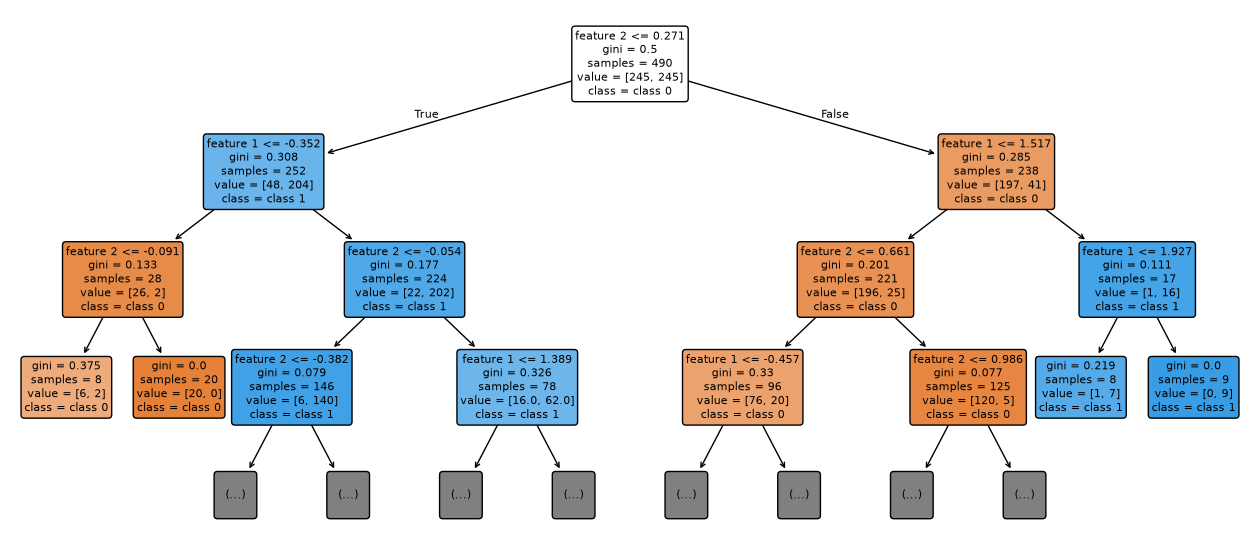

In [8]:
plt.figure(figsize=(16, 7))
plot_tree(models["Decision tree (depth 5)"], feature_names=["feature 1", "feature 2"], class_names=["class 0", "class 1"], filled=True, rounded=True, max_depth=3, fontsize=8)
plt.show()